

<div style="background-color:#172554; padding:30px; border-radius:12px; text-align:center;">
  <h1 style="color:white; font-size:32px; margin:0;">
    ✦ Monte-Carlo Simulation & Option Pricing ✦
  </h1>

  <hr style="width:60px; border:2px solid #818cf8;">
  <p style="text-align:center; font-size:16px; color:gray;">
    Pedro Afonso Gonçalves
</p>
</div>




**Objectif:** Estimer par simulation de Monte Carlo le prix et le delta d'un call européen dans le modèle de Black-Scholes, valider les estimateurs face aux formules fermées, mesurer le gain apporté par deux techniques de réduction de variance (variables antithétiques et variable de contrôle), puis implémenter brièvement le modèle d'Heston.

**Plan**
1. Cadre théorique
2. Outils : simulation et formules exactes
3. Prix par Monte Carlo et intervalle de confiance
4. Delta par estimateur pathwise
5. Réduction de variance
6. Modèle d'Heston et surface de vol
7. Limites et pistes d'extension

## 1. Cadre théorique

### 1.1 Modèle de Black-Scholes sous la probabilité risque-neutre $\mathbb{Q}$

Un actif risqué $S$ et un actif sans risque de taux constant $r$ :

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t, \qquad dB_t = rB_t\,dt .$$

La solution explicite est : 

$$S_t = S_0 \exp\!\Big(\big(r-\tfrac{\sigma^2}{2}\big)t + \sigma W_t\Big).$$

Comme $W_T \sim \sqrt{T}\,Z$ avec $Z\sim\mathcal N(0,1)$, on simule **exactement** la valeur terminale :

$$S_T = S_0 \exp\!\Big(\big(r-\tfrac{\sigma^2}{2}\big)T + \sigma\sqrt{T}\,Z\Big).$$


### 1.2 Prix d'un call européen

Par absence d'opportunité d'arbitrage, le prix en $0$ d'un call de strike $K$ et d'échéance $T$ est

$$C_0 = \mathbb{E}^{\mathbb{Q}}\!\left[e^{-rT}(S_T-K)^+\right].$$

Formule fermée de Black-Scholes (avec $\Phi$ la fonction de répartition de $\mathcal N(0,1)$) :

$$C_0 = S_0\,\Phi(d_1) - K e^{-rT}\Phi(d_2),\qquad
d_1=\frac{\ln(S_0/K)+\big(r+\tfrac{\sigma^2}{2}\big)T}{\sigma\sqrt{T}},\quad d_2=d_1-\sigma\sqrt{T}.$$

En t, on obtiens :

$$C_t = C(t,S_t), \qquad C(t,x)=\mathbb{E}\!\left[e^{-r(T-t)}\Big(x\,e^{(r-\frac{\sigma^2}{2})(T-t)+\sigma\sqrt{(T-t)}\,Z}-K\Big)^+\right].$$ en utilisant la propriété de markov du mouvement brownien et la propriété de martingale de l'actif actualisé sous la probabilité risque neutre $\mathbb{Q} $.

La formule exacte nous donne :
$$C_t = S_t\,\Phi(d_1) - K e^{-r(T-t)}\Phi(d_2),\qquad
d_1=\frac{\ln(S_t/K)+\big(r+\tfrac{\sigma^2}{2}\big)(T-t)}{\sigma\sqrt{T-t}},\quad d_2=d_1-\sigma\sqrt{T-t}.$$
### 1.3 Estimateur de Monte Carlo et intervalle de confiance

Avec $X_i = e^{-rT}(S_T^{(i)}-K)^+$ i.i.d., l'estimateur est $\hat C_n=\frac1n\sum_{i=1}^n X_i$. La loi forte des grands nombres donne $\hat C_n\to C_0$ p.s, et le théorème central limite donne

$$\sqrt n\,(\hat C_n - C_0)\ \xrightarrow{\ \mathcal L\ }\ \mathcal N(0,\mathrm{Var}(X_0)).$$

L'intervalle de confiance asymptotique à 95 % est

$$\hat C_n \pm 1{,}96\,\frac{\hat s_n}{\sqrt n},\qquad \hat s_n^2=\frac{1}{n-1}\sum_{i=1}^n (X_i-\hat C_n)^2 = \dfrac{n}{n-1} (\dfrac{1}{n}\sum_{i=1}^n X_i^2  - \hat C_n^2) .$$ 

La vitesse de convergence est donc en $O(1/\sqrt n)$, quel que soit le payoff : réduire la variance revient à gagner en précision à coût égal.

### 1.4 Delta

Le delta $\Delta_0=\partial C_0/\partial S_0$ vaut $\Phi(d_1)$ pour un call. Par la méthode **pathwise**, on dérive sous l'espérance. Comme $S_T$ est proportionnel à $S_0$, on a $\partial S_T/\partial S_0 = S_T/S_0$, d'où

$$\Delta_0 = \mathbb{E}^{\mathbb{Q}}\!\left[e^{-rT}\,\mathbf 1_{\{S_T>K\}}\,\frac{S_T}{S_0}\right].$$

La dérivation sous l'espérance est légitime car $x\mapsto(x-K)^+$ est lipschitzienne, donc dérivable sauf en $K$, et $\mathbb P(S_T=K)=0$.

On obtiens en t, 

$$ \Delta_t =  \mathbb{E}^{\mathbb{Q}}\!\left[ e^{-r(T-t)}\mathbf 1_{\{S_t.e^{(r-\dfrac{\sigma^2}{2})(T-t) + \sigma(W_T - W_t)}>K\}}\dfrac{S_T}{S_t}\right],$$ de la même façon que précèdemment ! 

## 2. Outils : simulation et formules exactes

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
import scipy.stats as stats
from IPython.display import HTML, display
from scipy.optimize import brentq

display(
    HTML(
        "<style>.jp-OutputArea-output, .output_png { display: flex; justify-content: center; }</style>"
    )
)

r = 0.01 ;  sigma = 0.2 ; nb = 10000 ; S0 = 100 ;  T = 1;  N = 100 ;  K = 100

[]

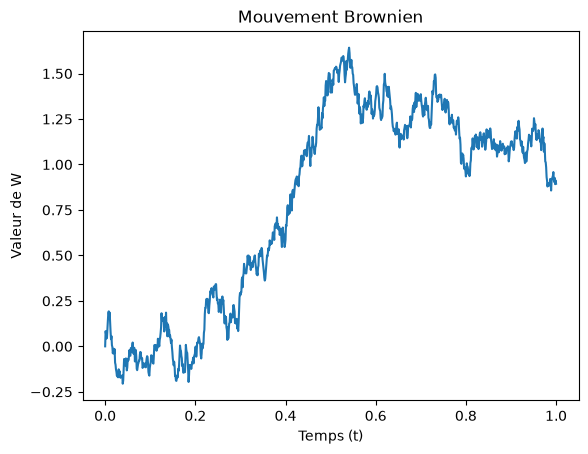

In [2]:
def BrownianMotion(T, N):
    t = np.linspace(0, T, N +1) 
    Norm = stats.norm( loc = 0, scale = np.sqrt(T/N))
    dW = Norm.rvs(N)
    W = np.zeros(N+1)
    W[1:] = np.cumsum( dW ) # permet de récupérer l'indépendance des incréments 
    return t, W

t, W = BrownianMotion( 1, 1000 ) 
fig, ax = plt.subplots()
ax.plot( t, W )
ax.set_title( " Mouvement Brownien " ) 
ax.set_xlabel( " Temps (t) " ) 
ax.set_ylabel( " Valeur de W " )  
plt.plot()

In [3]:
def risky_assets_prices( r, sigma, T, N, S0): # asset prices selon le modèle de B&S
    t, W = BrownianMotion( T, N ) 
    S = S0*np.exp( (r - 0.5*sigma**2 )*t + sigma*W ) 
    return t , W , S

def callput( x, K, option = "call"): # on définit la fonction callput : le payoff des options vanilles 
    if option == "call": 
        return np.maximum( 0, x - K) 
    else : 
        return np.maximum( 0, K - x ) 

def CallPut_price( S , K , t , T , sigma, r, model_opt = "call"): # permet de calculer le prix exact des options vanilles selon B&S
    norm = stats.norm( loc = 0, scale = 1 ) 
    dt = T - t
    dt_safe = np.where(dt == 0, 1e-12, dt)
    d1 = (np.log( S / (K*np.exp(-r*dt ))  ) + 0.5*dt*sigma**2  ) / (sigma*np.sqrt( dt_safe)) 
    d2 = (np.log( S / (K*np.exp(-r*dt ))  ) - 0.5*dt*sigma**2  ) / (sigma*np.sqrt( dt_safe ) )

    if model_opt == "call":
        return S*norm.cdf( d1 ) - K*np.exp(-r*dt )*norm.cdf( d2 ) 
    else : 
        return K*np.exp(-r*dt )*norm.cdf( -d2 ) - S*norm.cdf( -d1 ) 

def true_delta_func( S, K, r, t , T , sigma, model_opt = 'call'): # valeur exacte du delta d'une option vanille selon B&S
    dt = T - t
    dt_safe = np.where(dt == 0, 1e-12, dt)
    Norm = stats.norm( loc= 0, scale = 1)
    d1 = (np.log( S / K ) + r*dt_safe + 0.5*dt_safe*sigma**2  ) / (sigma*np.sqrt( dt_safe )) 
    if model_opt =='call':
        return Norm.cdf(d1) 
    else:
        return Norm.cdf(d1) - 1

def callput_derivative( x, K, model_opt = 'call'):
    if model_opt == 'call':
        return ( x >= K ).astype(int)
    else: 
        return  ( x <= K).astype(int)

C0_exact = CallPut_price( S0 , K , 0 , T , sigma, r)
delta_exact = true_delta_func( S0, K, r, 0 , T , sigma)
print(f"Prix exact Black-Scholes : {C0_exact:.4f}   |   Delta exact : {delta_exact:.4f}")


Prix exact Black-Scholes : 8.4333   |   Delta exact : 0.5596


## 3. Prix par Monte Carlo et intervalle de confiance

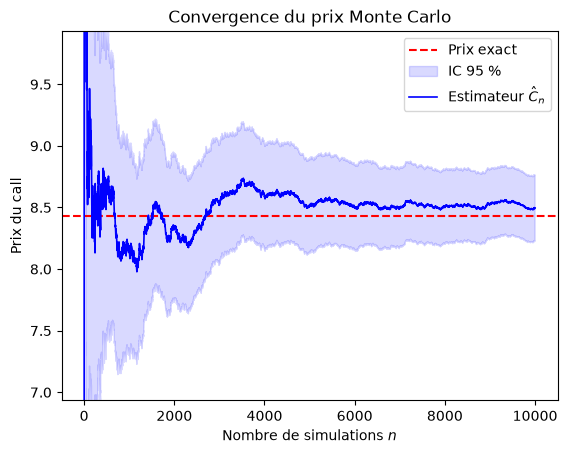

In [4]:
# on définit ici la fonction standard de ce notebook, qui est la fonction qui calcule le prix par monte carlo et exact d'un call sous B&S.
def option_computation( r, sigma, nb, S0, g, T, N, K): # nb = nombre d'itération et N = discrétisation du temps .
    payoff = []
    payoff_2 = []
    true_payoff = []
    n_iter = np.array (   [np.linspace(1, nb, nb )] * (N+1) ).T 
    for i in range(nb):
        t, W, S = risky_assets_prices(r, sigma, T, N, S0)
        dt =  T - t  
        dW =  W[-1] - W  
        pf_inter = np.exp( -r * dt ) * g( S * np.exp( (r-0.5*sigma**2)*dt + sigma*dW  ), K ) # permet de calculer l'estimateur du prix.
        pf2_inter = np.exp( -r * 2 * dt ) * g( S * np.exp( (r-0.5*sigma**2)*dt + sigma*dW  ), K )**2  # permet de calculer la variance de l'estimateur du prix .
        payoff.append( pf_inter )
        payoff_2.append( pf2_inter ) 
        true_pf_inter = CallPut_price( S, K, t, T, sigma,r ) # vrai prix en utilisant la formule close donné précèdemment.
        true_payoff.append(np.array(true_pf_inter)) 
    true_result = np.mean(true_payoff, axis = 0) 
    result = np.cumsum( np.array(payoff), axis = 0 ) / n_iter #  tableau: les colonnes sont le temps et les lignes sont les itérations.
    var_result = np.cumsum( np.array(payoff_2), axis = 0 ) / n_iter - result**2
    return t, result, true_result , var_result
    

# Extraction des données :

t, result_std, true_result ,result_var_std = option_computation( r, sigma, nb, S0, callput, T, N, K)
n_iter = np.linspace(1,nb,nb) 
price_est = result_std.T[0] # évolution de l'etimateur du prix en fonction du temps 
true_price_std = true_result[0] 
price_var = result_var_std.T[0] # évolution de l'estimateur de la variance en fonction de n 
std_err = np.sqrt(np.maximum(price_var,0)) / np.sqrt( n_iter ) 
ic_lower = price_est - 1.96*std_err # borne inf de l'intervalle de confiance 
ic_upper = price_est + 1.96*std_err # borne sup de l'intervalle de confiance

# Construction de la figure :

fig, ax = plt.subplots()
ax.axhline( true_price_std, c = 'r',ls="--", label="Prix exact") 
ax.fill_between( n_iter, ic_lower, ic_upper, color = 'b', alpha=0.15,label="IC 95 %")
ax.plot( n_iter, price_est, color = 'b',lw=1.2, label=r"Estimateur $\hat C_n$")
ax.set(xlabel="Nombre de simulations $n$", ylabel="Prix du call", title="Convergence du prix Monte Carlo")
ax.set_ylim(true_price_std - 1.5, true_price_std + 1.5)
ax.legend(); plt.show()

## 4. Delta par estimateur pathwise

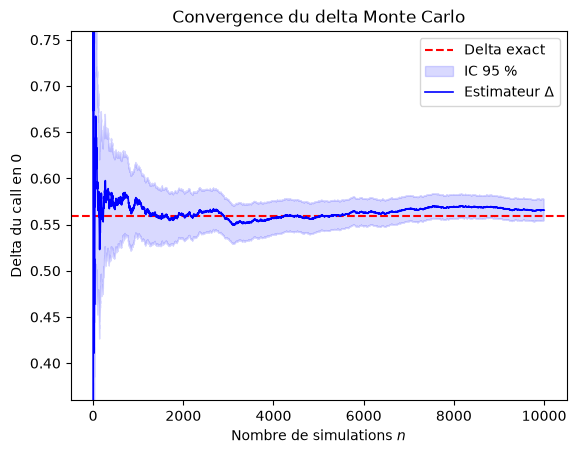

In [5]:
def delta_computation(r, sigma, nb, S0, g, T, N, K): # g est la dérivé de la fonction initiale du payoff 
    delta = []
    true_delta = []
    delta_var = []
    n_iter = np.array ( [np.linspace(1, nb, nb )] * (N+1) ).T 
    for i in range(nb):
        t, W, S = risky_assets_prices(r, sigma, T, N, S0)
        dt =  T - t  #np.array(  [ T ] * len(t) - t  )
        dW =  W[-1] - W   #np.array( [ W[ -1 ] ]* len(W) - W  ) 
        delta_inter = np.exp( -r * dt ) * g( S* np.exp( (r-0.5*sigma**2)*dt + sigma*dW  ) , K )  * np.exp( (r-0.5*sigma**2)*dt + sigma*dW  )
        delta_var_inter = delta_inter**2
        delta.append( delta_inter ) 
        true_delta_inter = true_delta_func( S, K, r, t , T, sigma) 
        true_delta.append( np.array(true_delta_inter) ) 
        delta_var.append( np.array(delta_var_inter) ) 
    true_result = np.mean( true_delta, axis = 0)
    result = np.cumsum( np.array(delta), axis = 0) /n_iter
    var = np.cumsum( np.array(delta_var), axis = 0) / n_iter - result**2
    return t, result, true_result,  var 

# Extraction des données en t = 0
t, delta_est, delta_true, delta_var = delta_computation(r, sigma, nb, S0, callput_derivative, T, N, K)

delta0 = delta_est.T[0]
delta0_var = delta_var.T[0]
true_delta0 = delta_true[0]

delta_err = np.sqrt( np.maximum(0, delta0_var) ) / np.sqrt( n_iter ) 
ic_lower =  delta0 - 1.96*delta_err
ic_upper = delta0 + 1.96*delta_err

# Création de la figure :

fig, ax = plt.subplots()
ax.axhline( true_delta0, c = 'r',ls="--", label="Delta exact")
ax.fill_between( n_iter, ic_lower, ic_upper, color = 'b', alpha=0.15,label="IC 95 %")
ax.plot( n_iter, delta0, color = 'b',lw=1.2, label=r"Estimateur $\Delta$")
ax.set(xlabel="Nombre de simulations $n$", ylabel="Delta du call en 0", title="Convergence du delta Monte Carlo")
ax.set_ylim(true_delta0 - 0.20, true_delta0 + 0.20)
ax.legend(); plt.show()


## 5. Réduction de variance

Pour comparer les méthodes honnêtement, on mesure l'**efficacité** : à variance égale, une méthode qui coûte deux fois plus d'évaluations du payoff doit être pénalisée. On compare donc $\mathrm{Var}(X)\cdot c_X$ à $\mathrm{Var}(Y)\cdot c_Y$, où $c$ est le coût relatif par échantillon.

### 5.1 Variables antithétiques

Si $Z\sim\mathcal N(0,1)$, alors $-Z$ a la même loi. En notant $g(Z)=e^{-rT}(S_T(Z)-K)^+$, on pose

$$Y = \frac{g(Z)+g(-Z)}{2}, \qquad \mathbb E[Y]=C_0,\qquad
\mathrm{Var}(Y)=\frac{\mathrm{Var}(X)+\mathrm{Cov}\big(g(Z),g(-Z)\big)}{2}.$$

Comme $g$ est monotone en $Z$, la covariance est négative : $\mathrm{Var}(Y)\le \mathrm{Var}(X)/2$. Chaque $Y_i$ coûte deux évaluations du payoff, donc $c_Y = 2$. L'IC se construit sur les $Y_i$ (i.i.d.) et non sur les $2n$ évaluations, qui ne sont pas indépendantes.


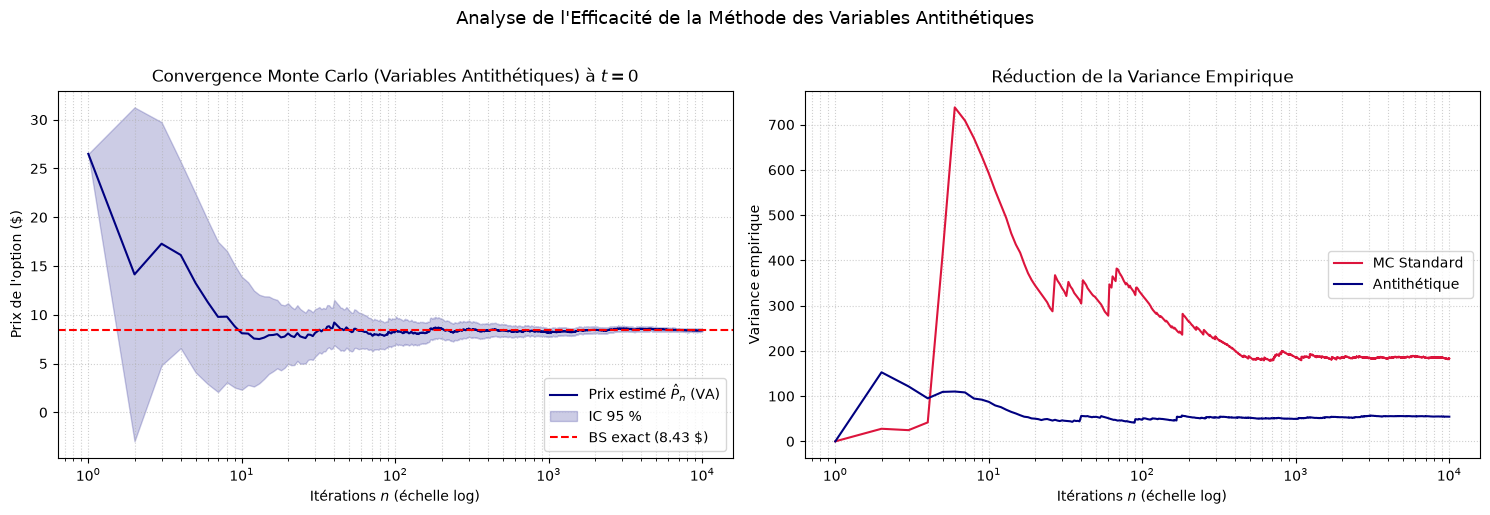

Réduction de variance obtenue : 40.37 %


In [6]:
# variable antithétique :

def option_computation_VA( r, sigma, nb, S0, g, T, N, K): # nb = nombre d'itération et N = discrétisation du temps 
    payoff = []
    payoff_2 = []
    true_payoff = []
    n_iter = np.array (   [np.linspace(1, nb, nb )] * (N+1) ).T 
    for i in range(nb):
        t, W = BrownianMotion( T , N ) 
        dt =  T - t  
        dW =  W[-1] - W   
        pf_inter = np.exp( -r * dt ) * g( ( S0 * np.exp(  (r - 0.5 * sigma**2)*t + sigma * W ) ) * np.exp( (r-0.5*sigma**2)*dt + sigma*dW  ), K )
        pf_inter_anti = np.exp( -r * dt ) * g( ( S0 * np.exp(  (r - 0.5 * sigma**2)*t - sigma * W ) ) * np.exp( (r-0.5*sigma**2)*dt - sigma*dW  ), K )
        pf2_inter = ((pf_inter + pf_inter_anti)/2 )**2
        payoff.append( (pf_inter + pf_inter_anti)/2 )
        payoff_2.append( pf2_inter ) 
        true_pf_inter = CallPut_price( S0 * np.exp(  (r - 0.5 * sigma**2)*t + sigma * W ), K, t, T, sigma,r )
        true_payoff.append(np.array(true_pf_inter)) 
    true_result = np.mean(true_payoff, axis = 0) 
    result = np.cumsum( np.array(payoff), axis = 0 ) / (n_iter) # c'est un tableau ou les colonnes sont le temps et les lignes sont les itérations 
    var_result = np.cumsum( np.array(payoff_2), axis = 0 ) / (n_iter) - result**2
    return t, result, true_result , var_result

t, result, true_result, var_result = option_computation( r, sigma, nb, S0, callput, T, N, K)
t_va, result_va, true_result_va, var_result_va = option_computation_VA( r, sigma, nb, S0, callput, T, N, K)

# On extrait l'instant 0 de true_result.
var_empirical_std = var_result.T[0]  # Converge vers Var(X)
var_empirical_va = var_result_va.T[0]    # Converge vers Var(X+X'/2)

# On se place à t = 0 (indice 0 après transposition)
idx_t = 0
n_iterations = np.arange(1, nb + 1)

# Écart-type empirique de la paire pour l'IC (TCL sur Y)   on prend alpha = 0,95
std_err_va = np.sqrt(var_empirical_va) / np.sqrt(n_iterations)
ic_low_va = result_va.T[0] - 1.96 * std_err_va
ic_up_va = result_va.T[0] + 1.96 * std_err_va

# 2. Création de la figure :
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Graphique 1 (Gauche) : Convergence MC Antithétique & IC 95 % ---
ax1.plot(n_iterations, result_va.T[idx_t], color="navy", lw=1.5, label=r"Prix estimé $\hat{P}_n$ (VA)")
ax1.fill_between(n_iterations, ic_low_va, ic_up_va, color="navy", alpha=0.2, label="IC 95 %")
ax1.axhline(true_result_va[idx_t], color="red", linestyle="--", lw=1.5, label=f"BS exact ({true_result_va[idx_t]:.2f} $)")

ax1.set_xscale("log")
ax1.set_xlabel("Itérations $n$ (échelle log)")
ax1.set_ylabel("Prix de l'option ($)")
ax1.set_title("Convergence Monte Carlo (Variables Antithétiques) à $t=0$")
ax1.grid(True, which="both", linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

# --- Graphique 2 (Droite) : Comparaison des Variances Empiriques ---
ax2.plot(n_iterations, var_empirical_std, color="crimson", lw=1.5, label=r"MC Standard ")
ax2.plot(n_iterations, var_empirical_va, color="navy", lw=1.5, label=r"Antithétique ")

ax2.set_xscale("log")
ax2.set_xlabel("Itérations $n$ (échelle log)")
ax2.set_ylabel("Variance empirique")
ax2.set_title(r"Réduction de la Variance Empirique")
ax2.grid(True, which="both", linestyle=":", alpha=0.6)
ax2.legend(loc="center right")

plt.suptitle("Analyse de l'Efficacité de la Méthode des Variables Antithétiques", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
# Affichage du gain de variance relatif
gain = (1 - var_empirical_va[-1]*2 / var_empirical_std[-1]) * 100 # en prenant en compte le coup de simulation.
print(f"Réduction de variance obtenue : {gain:.2f} %")

On remarque que malgrès le coup de simulation plus élevée de la méthode de réduction de variance antithétique, la réduction de variance est non négligeable. On obtiens donc des bornes plus fines pour notre intervalle de confiance ! 

### 5.2 Variable de contrôle

On cherche une variable $\theta$ de moyenne connue (ici nulle) et corrélée à $X$. Sous $\mathbb Q$, $\mathbb E[e^{-rT}S_T]=S_0$, donc

$$\theta = e^{-rT}S_T - S_0, \qquad \mathbb E[\theta]=0 .$$

Ce choix redonne la parité call-put : $\theta = X - X'$ où $X' = e^{-rT}(K-S_T)^+ + S_0 - Ke^{-rT}$ est l'estimateur du call obtenu à partir du put, car $e^{-rT}\big[(S_T-K)^+-(K-S_T)^+\big]=e^{-rT}(S_T-K)$. Les deux estimateurs $X$ et $X'$ ont la même espérance $C_0$.

On forme

$$Y_\lambda = X - \lambda\,\theta,\qquad \lambda^\star=\frac{\mathrm{Cov}(X,\theta)}{\mathrm{Var}(\theta)}=\frac{\mathbb E[X\theta]}{\mathbb E[\theta^2]},\qquad
\mathrm{Var}(Y_{\lambda^\star})=(1-\rho_{X,\theta}^2)\,\mathrm{Var}(X).$$



On pose, pour tout $k\ge 1$, les estimateurs suivants :

$$\theta_k = X_k - X'_k, \qquad X^{\lambda}_k = X_k - \lambda\,\theta_k .$$

Puis, pour toute taille de simulation $M\ge 1$ :

$$V_M := \frac{1}{M}\sum_{k=1}^{M}\theta_k^{2}, \qquad C_M := \frac{1}{M}\sum_{k=1}^{M}X_k\,\theta_k,$$

et

$$\lambda_M := \frac{C_M}{V_M} , \text{      avec la convention } \lambda_0 = 0.$$

Ce qui nous donne l'estimateur du prix suivant : 
$$ \qquad X^{\lambda}_M = \hat X_M - \lambda_M\,\hat\theta_M . $$

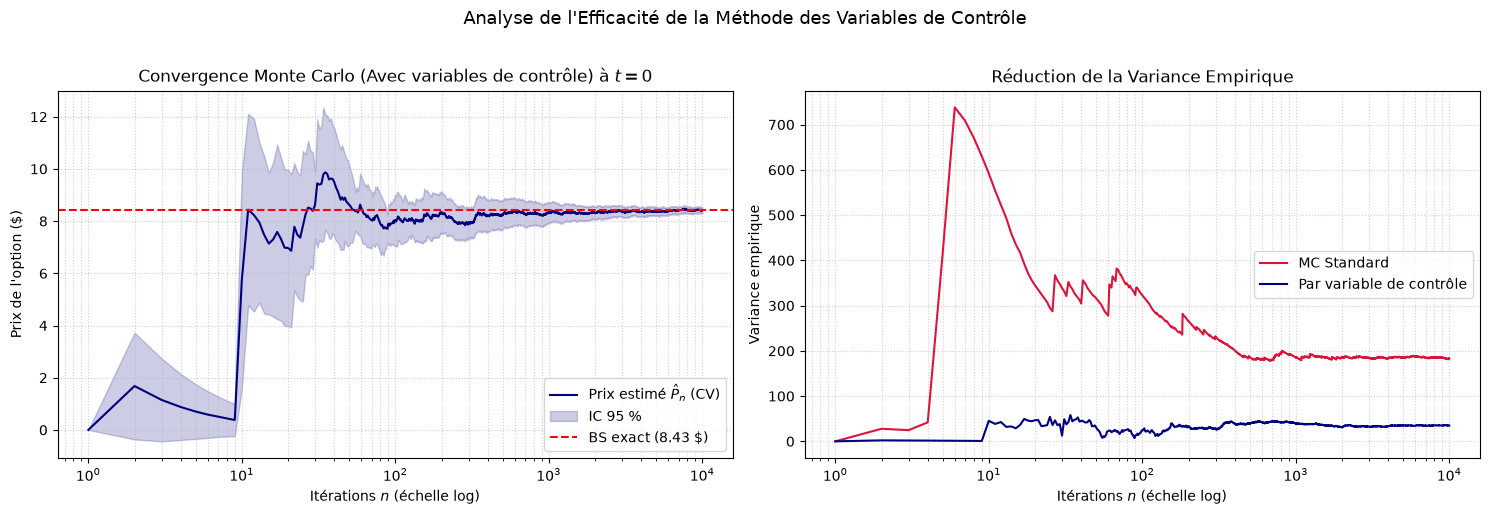

Réduction de variance obtenue : 80.89 %


In [7]:
# on fait dans cette section le calcul avec variable de contrôle, en utilisant la parité call-put :


def option_computation_CV(S0, T, nb, r, sigma, K, g ):
    n_iter = np.linspace(1,nb,nb) 
    norm = stats.norm( loc = 0, scale = 1 ) 
    G = norm.rvs(nb)
    S_T = S0 * np.exp( (r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*G ) 
    X_tab = np.exp(-r*T) * g(S_T,K)
    Xprim_tab = np.exp(-r*T) * g(S_T,K, option = "put") + S0 - K*np.exp(-r*T) 
    theta_tab = X_tab - Xprim_tab 
    lambd_tab_num = X_tab*theta_tab
    lambd_tab_den = theta_tab**2

    X = np.cumsum(X_tab)  / n_iter
    theta = np.cumsum(theta_tab) / n_iter 
    lambd = np.cumsum(lambd_tab_num)/ np.cumsum(lambd_tab_den) 
    var = ( np.cumsum( X_tab**2 ) / n_iter ) - X**2 - np.cumsum(lambd_tab_num)**2/ (np.cumsum( lambd_tab_den ) * n_iter ) 
    return X - lambd * theta , var 

result_CV, result_var_CV  = option_computation_CV( S0, T,nb,r,sigma,K, callput )  


# Écart-type empirique de la paire pour l'IC (TCL sur Y)   on prend alpha = 0,95
std_err_CV = np.sqrt(np.maximum(result_var_CV,0)) / np.sqrt(n_iter)
ic_low_CV = result_CV - 1.96 * std_err_CV
ic_up_CV = result_CV + 1.96 * std_err_CV

# 2. Création de la figure à 2 sous-graphiques
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Graphique 1 (Gauche) : Convergence MC CV & IC 95 % ---
ax1.plot(n_iterations, result_CV, color="navy", lw=1.5, label=r"Prix estimé $\hat{P}_n$ (CV)")
ax1.fill_between(n_iterations, ic_low_CV, ic_up_CV, color="navy", alpha=0.2, label="IC 95 %")
ax1.axhline(true_result_va[0], color="red", linestyle="--", lw=1.5, label=f"BS exact ({true_result_va[0]:.2f} $)")

ax1.set_xscale("log")
ax1.set_xlabel("Itérations $n$ (échelle log)")
ax1.set_ylabel("Prix de l'option ($)")
ax1.set_title("Convergence Monte Carlo (Avec variables de contrôle) à $t=0$")
ax1.grid(True, which="both", linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

# --- Graphique 2 (Droite) : Comparaison des Variances Empiriques ---
ax2.plot(n_iterations, var_empirical_std, color="crimson", lw=1.5, label=r"MC Standard ")
ax2.plot(n_iterations, result_var_CV, color="navy", lw=1.5, label=r"Par variable de contrôle")

ax2.set_xscale("log")
ax2.set_xlabel("Itérations $n$ (échelle log)")
ax2.set_ylabel("Variance empirique")
ax2.set_title(r"Réduction de la Variance Empirique")
ax2.grid(True, which="both", linestyle=":", alpha=0.6)
ax2.legend(loc="center right")

plt.suptitle("Analyse de l'Efficacité de la Méthode des Variables de Contrôle", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
# Affichage du gain de variance relatif
gain = (1 - result_var_CV[-1] / var_empirical_std[-1]) * 100
print(f"Réduction de variance obtenue : {gain:.2f} %")

On remarque une nouvelle fois, une réduction de variance significative, sachant que le coup de simulation est le même pour les deux méthodes 

### Conclusion

Les deux techniques réduisent la variance de l'estimateur du prix à coût de calcul comparable, et donc resserrent l'intervalle de confiance.

| Méthode | Coût par échantillon | Réduction de variance (à coût égal) | Précision gagnée |
|---|---|---|---|
| Monte Carlo standard | 1 | référence | référence |
| Variables antithétiques | 2 | ≈ 35-50 % | IC environ 20-30 % plus étroit |
| Variable de contrôle | 1 | ≈ 75-90 % | IC environ 50-60 % plus étroit |

- **Antithétiques** : le payoff étant monotone en $Z$, $g(Z)$ et $g(-Z)$ sont négativement corrélés, ce qui réduit la variance. Le gain reste modeste, car chaque paire coûte deux évaluations du payoff.
- **Variable de contrôle** : $\theta=e^{-rT}S_T-S_0$ est d'espérance connue (nulle) et fortement corrélée au payoff du call. La variance est multipliée par $1-\rho_{X,\theta}^2$, donc un gain de 82 % correspond à $\rho_{X,\theta}^2\approx 0{,}82$ (corrélation d'environ 0,9). Elle ne coûte rien de plus, puisque $\theta$ se calcule à partir du même $S_T$.
- **En pratique** : Pour les paramètres considérés, la variable de contrôle est la méthode la plus efficace. Elle permet d'obtenir une estimation plus précise du prix de l'option sans augmenter significativement le coût de calcul. 

## 6.Modèle d'Heston et surface de vol 

### Le modèle d'Heston :
\begin{align*}
	dS_t &=S_t \sqrt{V_t} dB_t, \quad d\langle W, B\rangle_t = \rho dt \\
	dV_t &= (\theta-\kappa V_t)dt + \eta \sqrt{V_t} dW_t, \quad V_0 \geq 0, S_0=1
\end{align*}
    
On a la fonction :
$$ \Phi_{T}(z) = \mathbb E\left[ \exp\left( \mathrm i z \log S_T \right) \right]$$

### Prix d'option vanille dans le cadre de ce modèle :
$$ \mathbb E (K-S_T)^+ = K - \frac {\sqrt{S_0K}}{\pi } \int_{\mathbb R_+} \Re \left(e^{izk} \frac{\Phi_T(z-\frac{i}{2})}{z^2 + \frac 1 4 }\right) dz,$$
avec $k=\log(S_0/K)$.

On obtiens ici le prix d'un put, on utilise la parité call/put pour obtenir le prix du call.

### La fonction $\Phi_T$

$$
\mathbb E[\exp\left(iv\log S_T \right) |\mathcal F_t]  = \exp\left( iv\log S_t + \phi(T-t)  + \psi(T-t) V_t  \right) 
$$
avec, 


\begin{align*}
\psi(t)&= \frac{\beta(v)-D(v)}{\eta^2}\frac{1-e^{-D(v)t}}{1-G(v)e^{-D(v)t}}\\
\phi(t)&= \frac{\theta}{\eta^2}\left((\beta(v)-D(v))t - 2 \log\left( \frac{G(v)e^{-D(v)t}-1}{G(v)-1} \right)\right)  \\
\beta(v) &= \kappa - iv \rho\eta, \quad  D(v)= \sqrt{\beta(v)^2  + \eta^2 v(i+v)}, \quad G(v) =\frac{\beta(v)-D(v)}{\beta(v)+ D(v)}.
\end{align*}

In [8]:
# On écrit d'abord toutes les fonctions utile :

ref_value_T1y = 0.05785155435  

kappa = 1.5768; theta = 0.0398*1.5768; V0 = 0.0175; rho = -0.5711; eta = 0.5751; r=0.; K = 1. ; s0 = 1.

def beta( v, rho, kappa, eta  ):
    return kappa - 1j*v*rho*eta
def D(v, rho, kappa, eta):
    return np.sqrt( beta(v, rho, kappa, eta)**2 + v*(1j+v)*eta**2 )
def G( v, rho, kappa, eta ):
    return ( beta(v, rho, kappa, eta ) - D(v,rho, kappa, eta ) ) / ( beta(v,rho, kappa, eta ) + D(v,rho, kappa, eta ) ) 
   
def psi( t , v ,rho, kappa, eta ):
    return (( beta(v,rho, kappa, eta ) - D(v,rho, kappa, eta ) )*(1 - np.exp( -D(v,rho, kappa, eta )*t ) ) ) /  ( (1 - G(v,rho, kappa, eta )*np.exp( -D(v,rho, kappa, eta )*t ))*eta**2 )   
def phi(t, v ,rho, kappa, eta ):
    coeff1 = theta/eta**2
    coeff2 =  beta(v,rho, kappa, eta ) - D(v,rho, kappa, eta )
    coeff3 = (  ( G(v,rho, kappa, eta )*np.exp(-D(v,rho, kappa, eta )*t) - 1  ) / ( G( v, rho, kappa, eta ) - 1 ) )  
    return coeff1*( coeff2*t - 2*np.log( coeff3 ) )

def PHI(tau, v, S, V , rho, kappa, eta ):
    return np.exp( 1j * v * np.log(S) + phi( tau, v ,rho, kappa, eta ) + psi( tau, v ,rho, kappa, eta )*V ) 



In [11]:
## On calcule ici le prix d'un put pour les valeurs donnée plus tôt, pour le calcul de l'intégrale, on passe par la méthode des trapèzes :
T = 1; N = 10000; Z = 1000; h = Z/(N-1); z = np.linspace( 0, Z, N) 

def call_price_heston( z, T, s0, V0, K, rho, kappa, eta ) :
    k = np.log( s0 / K ) 
    inter = np.exp( 1j*z*k ) * PHI( T , z - 1j/2, s0, V0, rho, kappa, eta  ) / ( z**2 + 0.25) 
    intégrale = (h/2) * ( inter[0].real + 2 * np.sum( inter[1:-1].real ) + inter[-1].real ) 
    put = K - (np.sqrt(s0*K)/np.pi) * intégrale
    call = put + s0 - K
    return call

print(f" La valeur obtenu par notre fonction: {call_price_heston( z,T,s0,V0,K,rho, kappa, eta ):.11f} | La valeur de référence : {ref_value_T1y}" ) 
print( f"On obtiens des valeurs très proches, l'écart entre ces deux valeurs est de : {((1 - call_price_heston( z,T,s0,V0,K,rho, kappa, eta )/ref_value_T1y )* 100):.10f} %" )

 La valeur obtenu par notre fonction: 0.05785155434 | La valeur de référence : 0.05785155435
On obtiens des valeurs très proches, l'écart entre ces deux valeurs est de : 0.0000000109 %


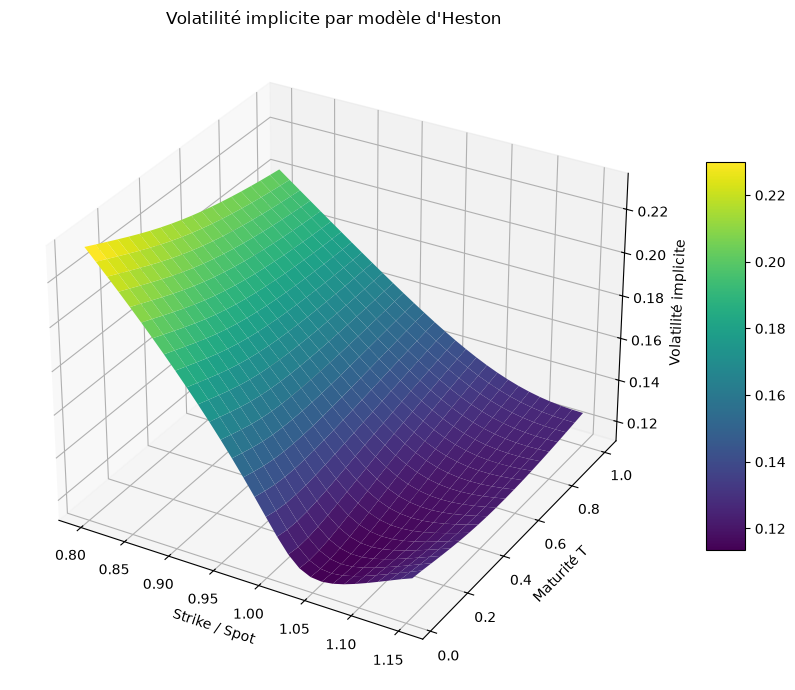

In [12]:
# On va récupérer ici la surface de vol pour K et T donnée dans un intervalle que l'on donne par la suite :

def invertible_func( z, T, N, s0, sigma, K, rho, kappa, eta, r = 0.): # nécessaire pour la méthode d'inversion que l'on va utiliser 
    return call_price_heston(z, T, s0, V0,K, rho, kappa, eta ) - CallPut_price( s0, K, 0., T, sigma,r)

def implied_vol( z, T, N, s0, K, rho, kappa, eta , r = 0.): # fonction permettant de récupérer la volatilité implicite à partir du modèle dh'eston et B&S
    def price_sigma( sigma ) :
        return invertible_func( z, T, N, s0, sigma, K, rho, kappa, eta , r = 0)
    try:
        # brentq ne fait varier QUE le premier argument de diff_price (sigma)
        return brentq(price_sigma, a=1e-4, b=5, xtol=1e-9, rtol=1e-9,maxiter=1000)
    except ValueError:
        return np.nan

#Write code

tab_T = np.linspace( 0.03, 1, 20) 
tab_K = np.linspace(0.8*s0, 1.15*s0, 30)

vol = np.zeros((len(tab_T), len(tab_K)))

for i, T in enumerate(tab_T):
    for j, K in enumerate(tab_K):
            iv = implied_vol(z, T, N, s0, K, rho, kappa, eta )
            vol[i, j] = iv

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
K_mesh,T_mesh = np.meshgrid(tab_K, tab_T)
surf = ax.plot_surface(K_mesh / s0, T_mesh, vol, cmap='viridis')

ax.set_xlabel("Strike / Spot")
ax.set_ylabel("Maturité T")
ax.set_zlabel("Volatilité implicite") 
ax.set_title("Volatilité implicite par modèle d'Heston")
fig.colorbar(surf, shrink=0.6, aspect=10)
plt.tight_layout()
plt.show()

On sait que dans le modèle de Black&Scholes, la volatilité est constante, on obtiendrai alors une surface plane à la place du graphe si dessus. Le graphe ci-dessus nous permet de dire que le modèle d'Heston capture des effets que le modèle de B&S ignore, i.e que la volatilité n'est pas constante. On remarque qu'a maturité fixé, la volatilité implicite diminue lorsque le strike augmente.

#### Regardons à T fixé ( $ T = 0.1$ ) comment la courbe de la volatilité implicite en fonction du strike change de forme en variant les valeurs de $\rho$:

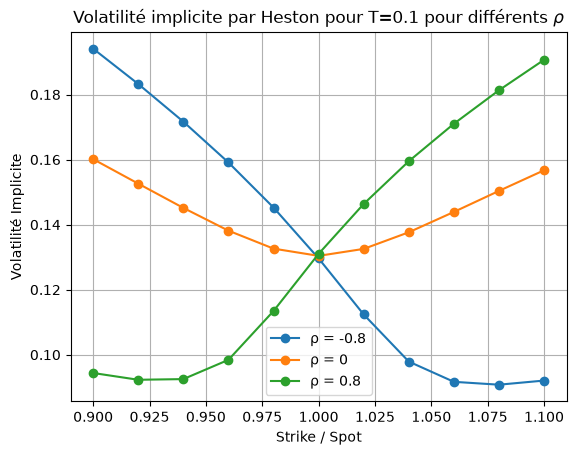

In [13]:
kappa = 1.5768; theta = 0.0398*1.5768; V0 = 0.0175; eta = 0.5751; r=0. ; s0 = 1. 
    
tab_K = np.linspace(0.9 * s0, 1.1 * s0, 11) ; N = 10000; Z = 1000; h = Z/(N-1); z = np.linspace( 0, Z, N); T = 0.1

rhos = [-0.8, 0, 0.8]

fig, ax = plt.subplots()
for rho in rhos:
    iv = np.array([implied_vol(z, T, N, s0, K, rho, kappa, eta ) for K in tab_K])
    ax.plot( tab_K / s0, iv, marker='o', label=f"ρ = {rho}")
ax.set_xlabel("Strike / Spot")
ax.set_ylabel("Volatilité Implicite")
ax.set_title(r"Volatilité implicite par Heston pour T=0.1 pour différents $\rho$")
plt.grid(True)
plt.legend()
plt.show()


On remarque avec ce graphique que la valeur de $ \rho $ donne le signe et l'amplitude du skew. Autrement dit, la valeur de $\rho$ donne la monotonie et l'amplitude du smile.

On donne la formule du skew suivante : 
$$    \mathrm{Skew}(T) = \frac{\partial \sigma_{\mathrm{impl}}(k,T)}{\partial k}$$ 

#### Regardons à T fixé ( $ T = 0.1$ ) comment la courbe de la volatilité implicite en fonction du strike change de forme en variant les valeurs de $\eta$:

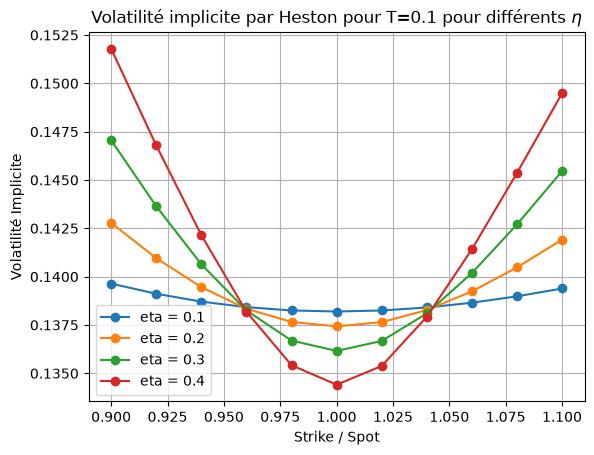

In [14]:
kappa = 1.5768; theta = 0.0398*1.5768; V0 = 0.0175; rho = 0.; r=0.; s0 = 1.

tab_K = np.linspace(0.9 * s0, 1.1 * s0, 11) ; N = 10000; Z = 1000; h = Z/(N-1); z = np.linspace( 0, Z, N); T = 0.1

etas = [0.1, 0.2, 0.3,  0.4]

fig, ax = plt.subplots()
for eta in etas:
    iv = np.array([implied_vol(z, T, N, s0, K, rho, kappa, eta ) for K in tab_K])
    ax.plot( tab_K / s0, iv, marker='o', label=f"eta = {eta}")
ax.set_xlabel("Strike / Spot")
ax.set_ylabel("Volatilité Implicite")
ax.set_title(r"Volatilité implicite par Heston pour T=0.1 pour différents $\eta$")
plt.grid(True)
plt.legend()
plt.show()

On remarque ici que le $\eta$ donne la courbure du smile.

### Conclusion

L'implémentation du modèle d'Heston par inversion de Fourier est validée : le prix à la monnaie coïncide avec la valeur de référence (écart de l'ordre de $10^{-8}\,\%$).

Contrairement à Black-Scholes, qui donne une surface de volatilité implicite plate, Heston produit une surface structurée :
- **Skew** : avec $\rho<0$, la vol implicite est plus élevée pour les strikes bas que pour les strikes hauts, comme sur les marchés actions.
- **Rôle de $\rho$** : il fixe le signe et l'amplitude du skew ($\rho<0$ : skew négatif, $\rho=0$ : smile symétrique, $\rho>0$ : skew inversé).
- **Rôle de $\eta$** : il contrôle la courbure du smile.
- **Maturité** : le skew est marqué aux maturités courtes et s'aplatit quand $T$ augmente, car le retour à la moyenne de la variance (vitesse $\kappa$) lisse l'effet.



## 7. Limites et pistes d'extension

- Les paramètres sont fixés et non calibrés sur des données de marché, la condition de Feller n'est pas vérifiée ($2\theta/\eta^2\approx 0{,}38<1$), la variance peut donc atteindre 0, l'intégrale est tronquée en $Z=1000$, ce qui peut dégrader la précision pour les très courtes maturités et les strikes extrêmes. On pourrait donc calibrer $(\kappa,\theta,\eta,\rho,V_0)$ sur des prix d'options réels, et simuler Heston par Monte Carlo (schéma d'Euler à troncature ou QE) pour pricer des options path-dépendantes, en réutilisant les techniques de réduction de variance de la partie 5.
- Le call européen admet une formule fermée, ce qui permet la validation. L'intérêt réel de Monte Carlo apparaît pour des payoffs path-dépendants (options asiatiques, à barrière), où les mêmes techniques de réduction de variance s'appliquent.

**Références** : G. Pagès : Numerical Probability : An Introduction with Applications to Finance, E. Abi Jaber : Cours M2 Probabilité et Finance (Modélisation stochastique).